In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, classification_report, ConfusionMatrixDisplay, auc, roc_curve, 
                            accuracy_score, precision_score, recall_score, f1_score,
                            roc_auc_score, confusion_matrix, 
                            )
from sklearn.cluster import KMeans 
from imblearn.pipeline import Pipeline   
from imblearn.over_sampling import SMOTE 


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [2]:
df = pd.read_excel("1688640705_hr_comma_sep.xlsx")

## Step 1 -- "Bacis Data Understanding"

In [3]:
df

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [4]:
print(f'Columns in the data : {df.columns}')

Columns in the data : Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'sales', 'salary'],
      dtype='object')


In [5]:
# Checking the null data in all the columns
df.isnull().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
sales                    0
salary                   0
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


In [7]:
df.left.value_counts()

left
0    11428
1     3571
Name: count, dtype: int64

In [8]:
df.left.value_counts(normalize=True)

left
0    0.761917
1    0.238083
Name: proportion, dtype: float64

In [9]:
df.sales.value_counts()

sales
sales          4140
technical      2720
support        2229
IT             1227
product_mng     902
marketing       858
RandD           787
accounting      767
hr              739
management      630
Name: count, dtype: int64

In [10]:
df.salary.value_counts(normalize=True)

salary
low       0.487766
medium    0.429762
high      0.082472
Name: proportion, dtype: float64

In [11]:
df.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


## Step 2 -- “EDA Insights: Key Drivers of Employee Attrition”

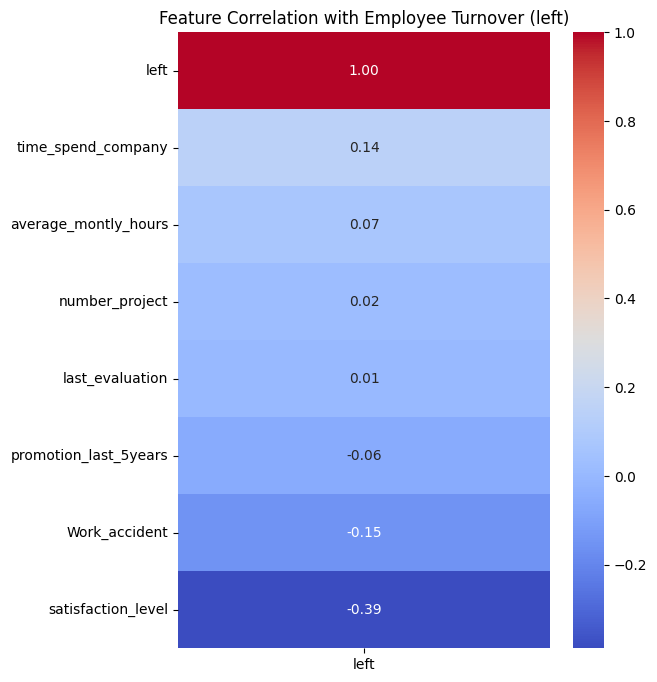

                           left
left                   1.000000
time_spend_company     0.144822
average_montly_hours   0.071287
number_project         0.023787
last_evaluation        0.006567
promotion_last_5years -0.061788
Work_accident         -0.154622
satisfaction_level    -0.388375


In [12]:
# Correlation analysis focused on target variable 'left'
corr_matrix = df.select_dtypes(include='number').corr()

target_corr = corr_matrix[['left']].sort_values(by='left', ascending=False)

plt.figure(figsize=(6,8))
sns.heatmap(target_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Feature Correlation with Employee Turnover (left)")
plt.show()

print(target_corr)


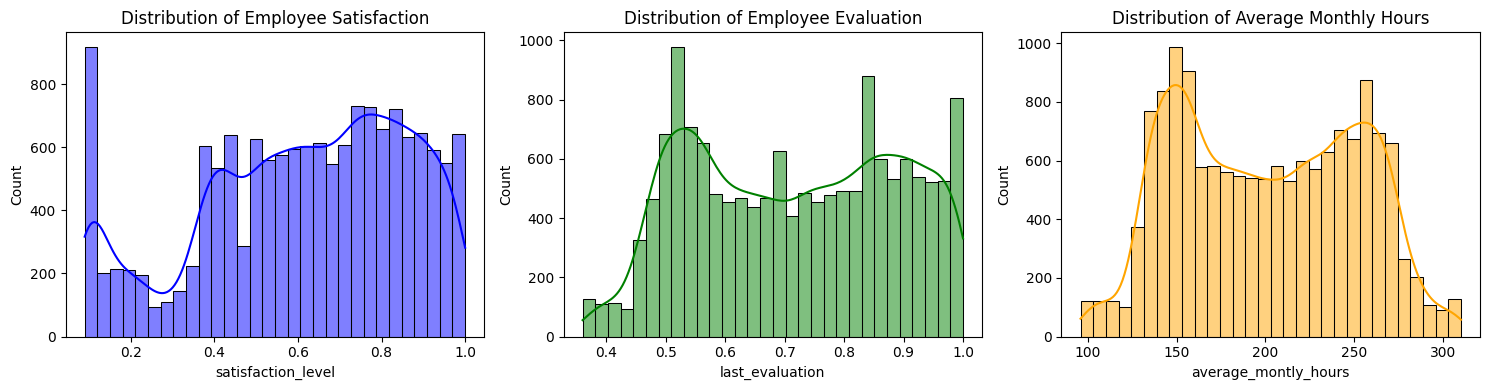

In [13]:
# 2.2 Drawing distribution plots for satisfaction_level, last_evaluation, average_montly_hours
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(df['satisfaction_level'], kde=True, bins=30, color='blue')
plt.title('Distribution of Employee Satisfaction')

plt.subplot(1, 3, 2)
sns.histplot(df['last_evaluation'], kde=True, bins=30, color='green')
plt.title('Distribution of Employee Evaluation')

plt.subplot(1, 3, 3)
sns.histplot(df['average_montly_hours'], kde=True, bins=30, color='orange')
plt.title('Distribution of Average Monthly Hours')

plt.tight_layout()
plt.show()

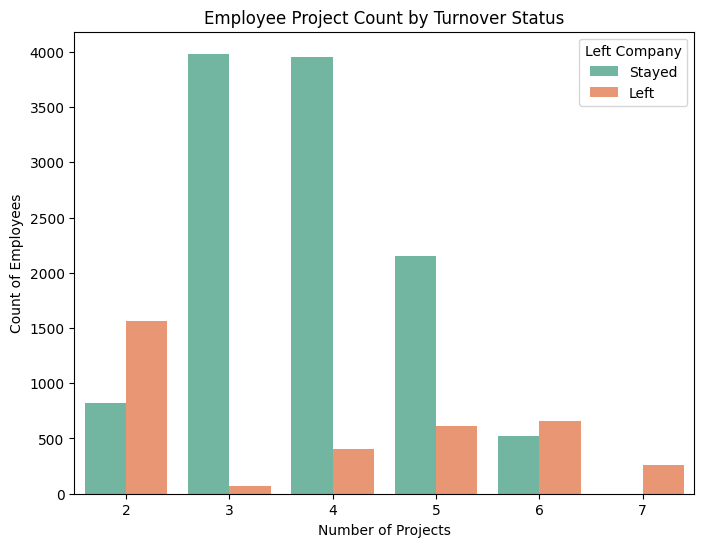

In [14]:
# 2.3 Draw bar plot of number_project count by left (employee turnover)
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='number_project', hue='left', palette='Set2')
plt.title('Employee Project Count by Turnover Status')
plt.xlabel('Number of Projects')
plt.ylabel('Count of Employees')
plt.legend(title='Left Company', labels=['Stayed', 'Left'])
plt.show()

### Inferences from the graph

1. **Workload Balance Matters**  
   - Too few projects → disengagement and higher turnover.  
   - Moderate projects → optimal retention zone.  
   - Higher projects → smaller group, but relatively stable.  

2. **Retention Strategy Insight**  
   - Assigning employees at least 3 projects seems to reduce attrition risk.  
   - Overloading isn't a major issue here, but underloading clearly is.  

3. **Possible Organizational Implication**  
   - Employees leaving with only 2 projects may reflect poor role fit, lack of growth opportunities, or insufficient challenge.  
   - Retention programs could focus on ensuring employees are meaningfully engaged with at least 3 projects.  


## Step 3 -- “Employee Attrition Clusters: Satisfaction vs Evaluation”

In [15]:
# Selecting relevant columns
df_left = df[df['left'] == 1][['satisfaction_level', 'last_evaluation']]
df_left = df[df['left'] == 1][['satisfaction_level', 'last_evaluation']]
df_left

,satisfaction_level,last_evaluation
0,0.38,0.53
1,0.80,0.86
2,0.11,0.88
3,0.72,0.87
4,0.37,0.52
...,...,...
14994,0.40,0.57
14995,0.37,0.48
14996,0.37,0.53
14997,0.11,0.96


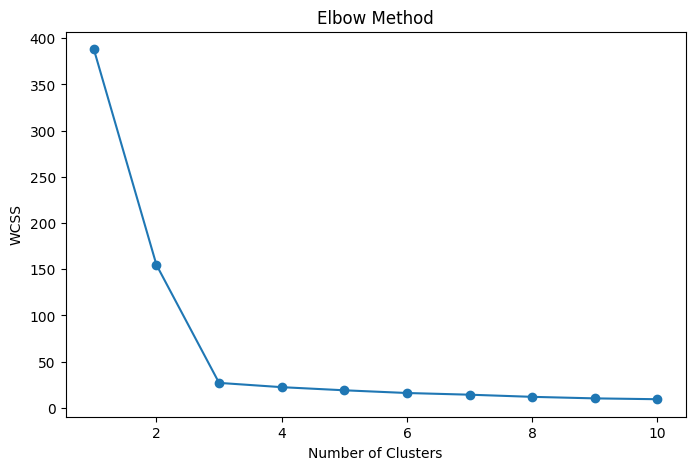

In [16]:
# Elbow Method - Determine optimal number of clusters
wcss = []

for i in range(1, 11):
    km = KMeans(n_clusters=i, random_state=42, n_init=10)
    km.fit(df_left[['satisfaction_level', 'last_evaluation']])
    wcss.append(km.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1,11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

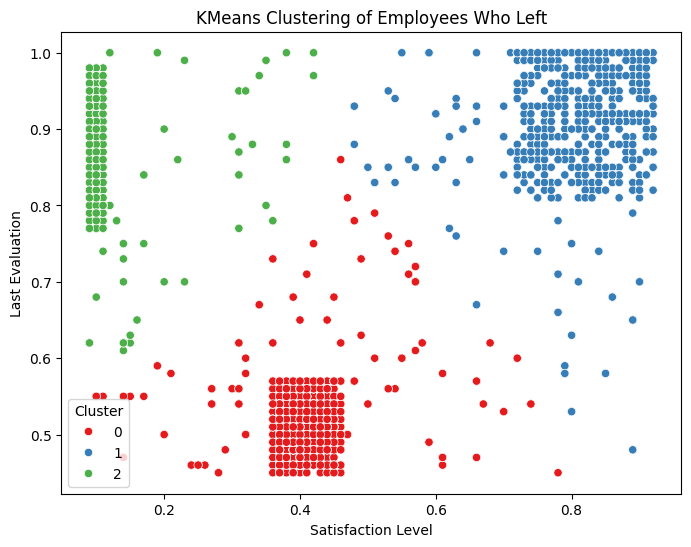

Cluster Centers (Satisfaction Level, Last Evaluation):
Cluster 0: [0.41014545 0.51698182]
Cluster 1: [0.80851586 0.91170931]
Cluster 2: [0.11115466 0.86930085]


In [17]:
## Performing clustering of Employees who left based on their satisfaction and evaluation.
# KMeans clustering with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42)
df_left['cluster'] = kmeans.fit_predict(df_left)

# Plot clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_left, x='satisfaction_level', y='last_evaluation', hue='cluster', palette='Set1')
plt.title('KMeans Clustering of Employees Who Left')
plt.xlabel('Satisfaction Level')
plt.ylabel('Last Evaluation')
plt.legend(title='Cluster')
plt.show()

# Cluster centers
centers = kmeans.cluster_centers_
print("Cluster Centers (Satisfaction Level, Last Evaluation):")
for index, center in enumerate(centers):
    print(f"Cluster {index}: {center}")


In [18]:
# Silhouette Score for Cluster Validation
sil_score = silhouette_score(
    df_left[['satisfaction_level', 'last_evaluation']],
    df_left['cluster']
)

print("Silhouette Score:", round(sil_score, 3))

Silhouette Score: 0.796


Cluster Summary Based on Original Features


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company
cluster,,,,,
0,0.41,0.52,2.18,150.09,3.07
1,0.81,0.91,4.51,241.86,5.04
2,0.11,0.87,6.12,271.98,4.08


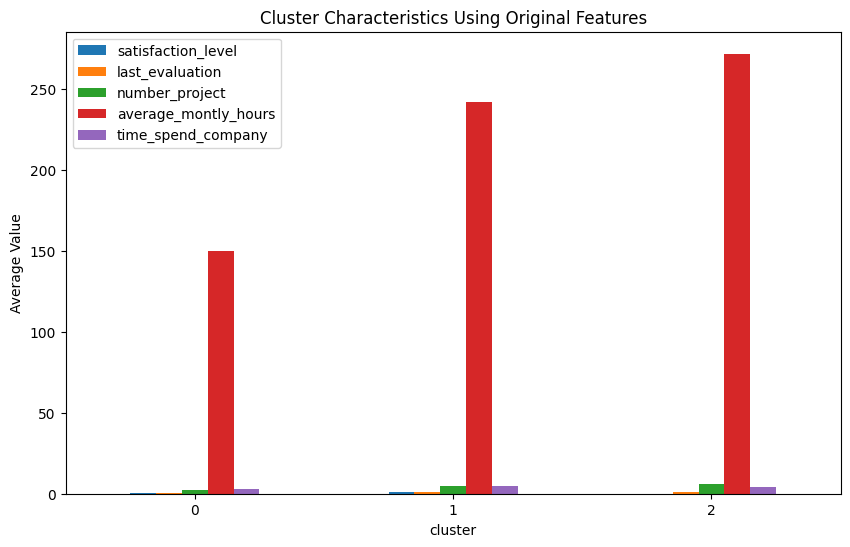

In [19]:
# Cluster summary using ORIGINAL features (not PCA components)
clustered_employees = df[df['left']==1].copy()
clustered_employees['cluster'] = df_left['cluster'].values

cluster_summary = clustered_employees.groupby('cluster')[[
    'satisfaction_level',
    'last_evaluation',
    'number_project',
    'average_montly_hours',
    'time_spend_company'
]].mean().round(2)

print("Cluster Summary Based on Original Features")
display(cluster_summary)

cluster_summary.plot(kind='bar', figsize=(10,6))
plt.title('Cluster Characteristics Using Original Features')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.show()


### Decoding Employee Exit Patterns: Satisfaction vs Evaluation
🔴 Cluster 0 (Red)
Low satisfaction, varying evaluation scores  
These employees are disengaged despite sometimes having decent evaluations.

Insight: Dissatisfaction is the dominant factor here. Even if they perform adequately, their unhappiness drives turnover.

Action: Focus on morale boosters — recognition, workload balance, or addressing workplace culture.

🔵 Cluster 1 (Blue)
Moderate satisfaction, moderate evaluation  
This group sits in the middle — neither highly satisfied nor highly evaluated.

Insight: They represent the “at-risk” segment. With the right support, they could be retained, but without intervention, they may drift toward leaving.

Action: Targeted training, career growth opportunities, and mentorship could shift them upward.

🟢 Cluster 2 (Green)
High satisfaction, high evaluation  
These employees are both happy and performing well.

Insight: They’re the most valuable group, but the fact that some still left suggests external factors (better offers, career shifts).

Action: Retention strategies like promotions, competitive pay, and long-term career paths are critical here.

## Step 4 -- “Data Preparation and Oversampling with SMOTE”

In [20]:
# 4.1 Pre-process data: separate categorical and numeric variables
numeric_cols = df.select_dtypes(include=['number']).columns.drop('left')  # exclude target column
categorical_cols = df.select_dtypes(include=['object']).columns

# Apply get_dummies to categorical variables
df_cat = pd.get_dummies(df[categorical_cols], drop_first=True)
df_num = df[numeric_cols]

# Combine numeric and encoded categorical variables
X = pd.concat([df_num, df_cat], axis=1)
y = df['left']

# 4.2 Stratified train-test split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=123
)

# 4.3 Upsample train data using SMOTE(I do this step in step5 which is the modern approach)
#smote = SMOTE(random_state=42)
#X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

## Step 5 -- “Comparative Evaluation of Classification Models”

In [21]:
logistic_pipeline = Pipeline([
    ('smote', SMOTE(random_state=123)),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

rf_pipeline = Pipeline([
    ('smote', SMOTE(random_state=123)),
    ('classifier', RandomForestClassifier(random_state=42))
])

gb_pipeline = Pipeline([
    ('smote', SMOTE(random_state=123)),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

# Models to evaluate
models = {
    'Logistic Regression': logistic_pipeline,
    'Random Forest': rf_pipeline,
    'Gradient Boosting': gb_pipeline
}

# Stratified 5-Fold cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Dictionaries to store aggregated results for Step 6
all_y_true_dict = {}
all_y_pred_dict = {}
all_y_prob_dict = {}

# Training with 5-Fold CV, collecting predictions and probabilities
for model_name, model in models.items():
    print(f"\nModel: {model_name}")
    
    all_y_true = []
    all_y_pred = []
    all_y_prob = []
    
    fold=1
    for train_index, val_index in skf.split(X, y):
        X_train_fold, X_val_fold = X.iloc[train_index], X.iloc[val_index]
        y_train_fold, y_val_fold = y.iloc[train_index], y.iloc[val_index]
        
        # Pipeline Training
        model.fit(X_train_fold, y_train_fold)
        
        y_pred = model.predict(X_val_fold)
        y_prob = model.predict_proba(X_val_fold)[:, 1]  # Probabilities for positive class
        
        all_y_true.extend(y_val_fold)
        all_y_pred.extend(y_pred)
        all_y_prob.extend(y_prob)
        
        print(f"Fold {fold} Classification Report:")
        print(classification_report(y_val_fold, y_pred))
        fold+=1
    
    print(f"Overall Classification Report for {model_name}:")
    print(classification_report(all_y_true, all_y_pred))
    
    # Store for Step 6
    all_y_true_dict[model_name] = all_y_true
    all_y_pred_dict[model_name] = all_y_pred
    all_y_prob_dict[model_name] = all_y_prob


Model: Logistic Regression
Fold 1 Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.78      0.83      2285
           1       0.50      0.72      0.59       715

    accuracy                           0.76      3000
   macro avg       0.70      0.75      0.71      3000
weighted avg       0.80      0.76      0.77      3000

Fold 2 Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.77      0.84      2286
           1       0.51      0.75      0.61       714

    accuracy                           0.77      3000
   macro avg       0.71      0.76      0.72      3000
weighted avg       0.81      0.77      0.78      3000

Fold 3 Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.79      0.84      2286
           1       0.52      0.72      0.60       714

    accuracy                           0.77      3000
   macro a

In [22]:
# Define pipeline with SMOTE + RandomForest
rf_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Parameter grid (note the prefix 'classifier__')
param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [5, 10, 15],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

# GridSearchCV on the pipeline
grid_search = GridSearchCV(
    estimator=rf_pipeline,   # <-- pipeline, not raw model
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

# Fit on original training data (without manual SMOTE)
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest ROC-AUC:")
print(grid_search.best_score_)

best_rf_pipeline = grid_search.best_estimator_

Best Parameters:
{'classifier__max_depth': 15, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best ROC-AUC:
0.9918200008327649


##### Additional code snippet which represent -- Imporatant Feature(highest to lowest)

                 Feature  Importance  Importance_Percentage
0     satisfaction_level    0.283430              28.343018
4     time_spend_company    0.236049              23.604852
2         number_project    0.150723              15.072282
3   average_montly_hours    0.133060              13.305960
1        last_evaluation    0.129172              12.917178
5          Work_accident    0.019141               1.914090
16            salary_low    0.011472               1.147202
17         salary_medium    0.008209               0.820913
15       sales_technical    0.006638               0.663841
14         sales_support    0.004760               0.476008


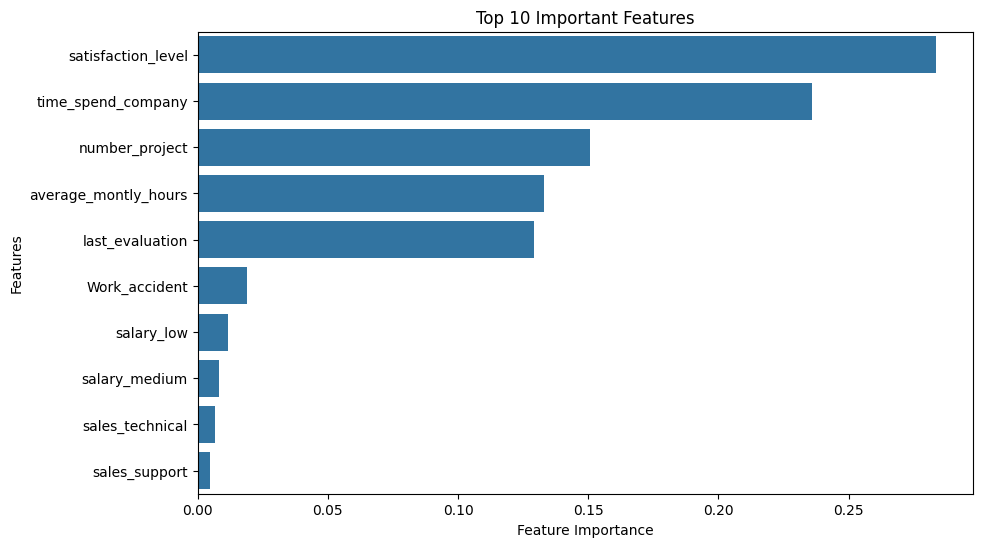

In [23]:
# Fit the best pipeline on original training data
best_rf_pipeline.fit(X_train, y_train)

# Extract Random Forest classifier from pipeline
rf_classifier = best_rf_pipeline.named_steps['classifier']

# Imporatant Feature, represented in DataFrame
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_classifier.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

# Add percentage contribution
feature_importance['Importance_Percentage'] = (
    feature_importance['Importance'] / feature_importance['Importance'].sum()
) * 100

print(feature_importance.head(10))

# Plot top 10 features
plt.figure(figsize=(10,6))
sns.barplot(data=feature_importance.head(10), x='Importance', y='Feature')
plt.title('Top 10 Important Features')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.show()

### Business Insights

1. Employees with low satisfaction levels are more likely to leave.
2. Employees working excessive monthly hours show higher turnover probability.
3. Employees with fewer promotions tend to leave more frequently.
4. High project workload contributes significantly to attrition.


## Step 6 -- “Best Model Selection with ROC Curves and Precision–Recall Trade-offs”

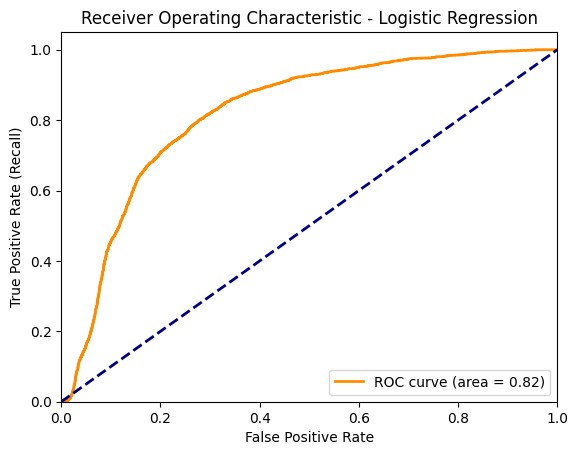

AUC for Logistic Regression: 0.82


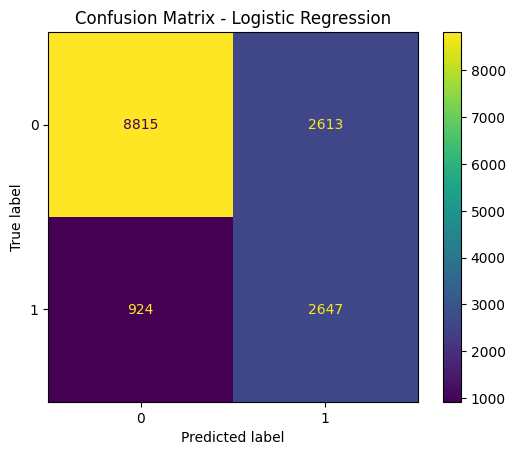

Classification Report for Logistic Regression:
              precision    recall  f1-score   support

           0       0.91      0.77      0.83     11428
           1       0.50      0.74      0.60      3571

    accuracy                           0.76     14999
   macro avg       0.70      0.76      0.72     14999
weighted avg       0.81      0.76      0.78     14999



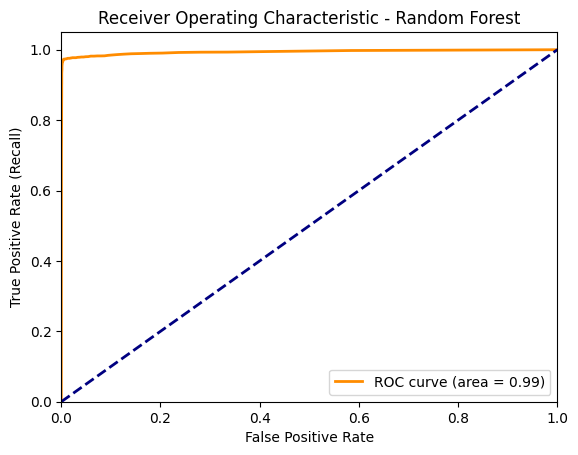

AUC for Random Forest: 0.99


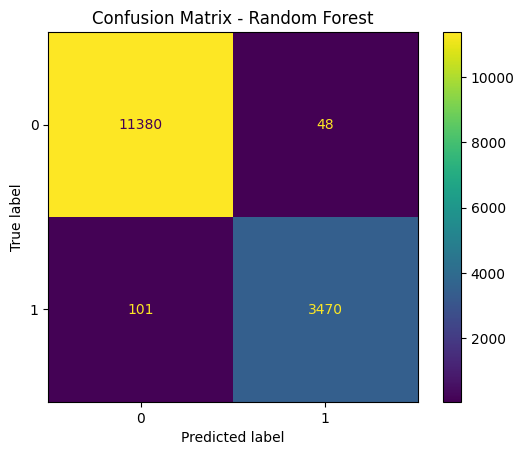

Classification Report for Random Forest:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     11428
           1       0.99      0.97      0.98      3571

    accuracy                           0.99     14999
   macro avg       0.99      0.98      0.99     14999
weighted avg       0.99      0.99      0.99     14999



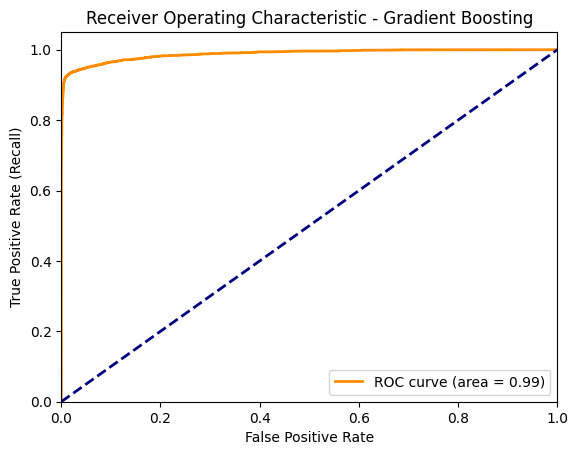

AUC for Gradient Boosting: 0.99


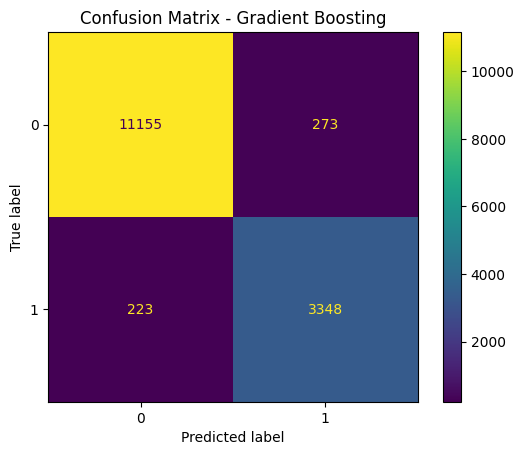

Classification Report for Gradient Boosting:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11428
           1       0.92      0.94      0.93      3571

    accuracy                           0.97     14999
   macro avg       0.95      0.96      0.95     14999
weighted avg       0.97      0.97      0.97     14999


Best Model based on AUC: Random Forest with AUC = 0.99

    In employee turnover prediction, Recall is prioritized because:
    - False Negatives (employees who leave but predicted to stay) are costly.
    - High Recall helps identify most leaving employees for retention.
    - Precision is secondary to avoid unnecessary retention efforts.
    


In [24]:
# Step 6: Use predictions from Step 5 to plot ROC, confusion matrix, and justify metrics
roc_auc_scores = {}

for model_name in models.keys():
    y_true = all_y_true_dict[model_name]
    y_pred = all_y_pred_dict[model_name]
    y_prob = all_y_prob_dict[model_name]
    
    # Compute ROC curve and AUC
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    roc_auc_scores[model_name] = roc_auc
  
    # Plot ROC curve
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate (Recall)')
    plt.title(f'Receiver Operating Characteristic - {model_name}')
    plt.legend(loc="lower right")
    plt.show()
    
    print(f"AUC for {model_name}: {roc_auc:.2f}")
    
    # Plot confusion matrix
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.show()
    
    # Print classification report again for reference
    print(f"Classification Report for {model_name}:")
    print(classification_report(y_true, y_pred))

# Identify best model by highest AUC
best_model_name = max(roc_auc_scores, key=roc_auc_scores.get)
print(f"\nBest Model based on AUC: {best_model_name} with AUC = {roc_auc_scores[best_model_name]:.2f}")

# Justification of metric choice based on confusion matrix for Random Forest (best model)
if best_model_name == 'Random Forest':
    explanation = """
    In employee turnover prediction, Recall is prioritized because:
    - False Negatives (employees who leave but predicted to stay) are costly.
    - High Recall helps identify most leaving employees for retention.
    - Precision is secondary to avoid unnecessary retention efforts.
    """
    print(explanation)
else:
    print("Analyze confusion matrix to decide whether Recall or Precision is more important based on your problem context.")

Accuracy : 0.9843333333333333
Precision: 0.9784791965566715
Recall   : 0.9551820728291317
F1 Score : 0.966690290574061
ROC AUC  : 0.9947472864911494


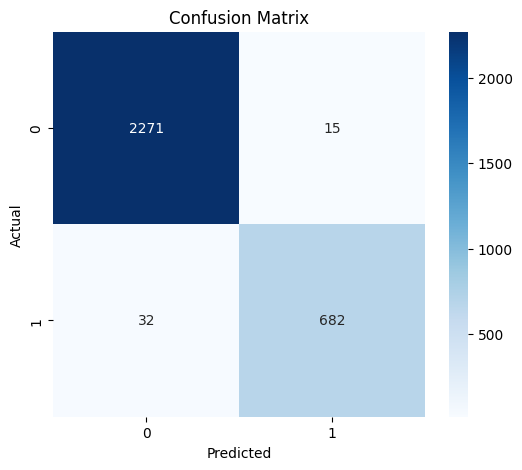

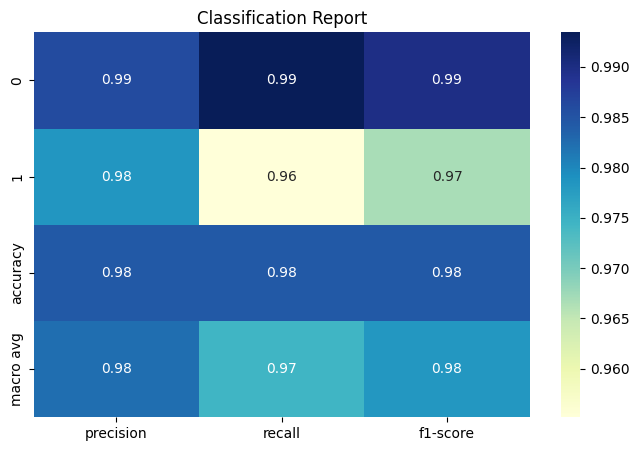

In [25]:
# Final Test Set Evaluation Using Tuned Random Forest
y_pred = best_rf_pipeline.predict(X_test)
y_prob = best_rf_pipeline.predict_proba(X_test)[:,1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC AUC  :", roc_auc_score(y_test, y_prob))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

plt.figure(figsize=(8,5))
sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap='YlGnBu')
plt.title('Classification Report')
plt.show()

## Step 7 -- “Retention Strategies Guided by Probability-Based Risk Zones”

In [26]:
# Assuming best_model_name and models dict from previous steps
best_model = models[best_model_name]

# Step 7.1: Predict turnover probabilities on test data
y_test_prob = best_model.predict_proba(X_test)[:, 1]  # Probability of leaving

# Step 7.2: Categorize employees into risk zones based on probability score
def categorize_risk(prob):
    if prob < 0.20:
        return 'Safe Zone (Green)'
    elif 0.20 <= prob < 0.60:
        return 'Low Risk Zone (Yellow)'
    elif 0.60 <= prob < 0.90:
        return 'Medium Risk Zone (Orange)'
    else:
        return 'High Risk Zone (Red)'

risk_zones = pd.Series(y_test_prob).apply(categorize_risk)

# Combine with employee IDs or indices if available
results_df = pd.DataFrame({
    'Turnover_Probability': y_test_prob,
    'Risk_Zone': risk_zones
})

# Count employees in each zone
zone_counts = results_df['Risk_Zone'].value_counts()
print("Employee counts by risk zone:")
print(zone_counts)

# Retention strategy suggestions template
print("\nRetention Strategy Suggestions:")

print("\nSafe Zone (Green) - Score < 20%:")
print("- Continue regular engagement and recognition programs.")
print("- Monitor for any changes in satisfaction or workload.")

print("\nLow Risk Zone (Yellow) - 20% < Score < 60%:")
print("- Provide targeted training and career development opportunities.")
print("- Conduct periodic check-ins to address concerns early.")

print("\nMedium Risk Zone (Orange) - 60% < Score < 90%:")
print("- Initiate personalized retention plans.")
print("- Offer incentives, flexible work options, or role adjustments.")
print("- Increase manager support and feedback frequency.")

print("\nHigh Risk Zone (Red) - Score > 90%:")
print("- Immediate intervention with retention specialists.")
print("- Consider tailored compensation or promotion discussions.")
print("- Address specific dissatisfaction factors urgently.")

# Optionally, save results for further analysis
# results_df.to_csv('employee_turnover_risk_zones.csv', index=False)

Employee counts by risk zone:
Risk_Zone
Safe Zone (Green)            2245
High Risk Zone (Red)          683
Low Risk Zone (Yellow)         47
Medium Risk Zone (Orange)      25
Name: count, dtype: int64

Retention Strategy Suggestions:

Safe Zone (Green) - Score < 20%:
- Continue regular engagement and recognition programs.
- Monitor for any changes in satisfaction or workload.

Low Risk Zone (Yellow) - 20% < Score < 60%:
- Provide targeted training and career development opportunities.
- Conduct periodic check-ins to address concerns early.

Medium Risk Zone (Orange) - 60% < Score < 90%:
- Initiate personalized retention plans.
- Offer incentives, flexible work options, or role adjustments.
- Increase manager support and feedback frequency.

High Risk Zone (Red) - Score > 90%:
- Immediate intervention with retention specialists.
- Consider tailored compensation or promotion discussions.
- Address specific dissatisfaction factors urgently.
